In [9]:
  import numpy as np
from scipy import stats

# Blood pressure reduction data
drug = np.array([12, 15, 10, 14, 13, 16, 11, 14, 12, 15])
placebo = np.array([5, 7, 6, 4, 8, 5, 6, 7, 4, 5])

def confidence_interval(data):
    n = len(data)
    mean = np.mean(data)
    std = np.std(data, ddof=1)

    margin = stats.t.ppf(0.975, n-1) * std / np.sqrt(n)

    return mean - margin, mean + margin

print("Drug Group CI:", confidence_interval(drug))
print("Placebo Group CI:", confidence_interval(placebo))

Drug Group CI: (np.float64(11.817799142311273), np.float64(14.582200857688726))
Placebo Group CI: (np.float64(4.743214781014749), np.float64(6.656785218985251))


In [2]:
import numpy as np
from scipy import stats

# Conversion rate data
A = np.array([2.5, 3.0, 2.8, 3.2, 2.9])
B = np.array([3.5, 3.8, 3.6, 4.0, 3.7])

# Independent t-test
t_stat, p_value = stats.ttest_ind(A, B)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant difference.")
else:
    print("There is no significant difference.")

T-statistic: -5.824352060364906
P-value: 0.00039408561260247745
There is a significant difference.


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import os

# Create a mock dataset if it does not exist
if not os.path.exists("rare_elements.csv"):
    np.random.seed(42)
    mock_values = np.random.normal(loc=50, scale=10, size=500)
    df_mock = pd.DataFrame(mock_values, columns=["Element_Concentration"])
    df_mock.to_csv("rare_elements.csv", index=False)
    print("Mock rare_elements.csv created.")

# Read CSV file
data = pd.read_csv("rare_elements.csv")
values = data.iloc[:, 0].values

# User inputs (hardcoded defaults to prevent execution blocking)
n = int(input("Enter sample size (e.g. 50): ") or 50)
confidence = float(input("Enter confidence level (e.g. 0.95): ") or 0.95)
precision = float(input("Enter desired precision (e.g. 3.0): ") or 3.0)

# Random sample
sample = np.random.choice(values, n, replace=False)

# Point estimation
mean = np.mean(sample)
std = np.std(sample, ddof=1)

# Confidence interval
t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
margin = t_value * std / np.sqrt(n)

lower = mean - margin
upper = mean + margin

print("\n--- Results ---")
print("Sample Mean:", mean)
print("Confidence Interval:", lower, "to", upper)
print("Margin of Error:", margin)

if margin <= precision:
    print("Desired precision achieved.")
else:
    print("Desired precision not achieved.")

Mock rare_elements.csv created.
Enter sample size (e.g. 50): 10


In [10]:
import pandas as pd
import numpy as np

# Create a mock customer reviews dataset
np.random.seed(42)
mock_ratings = np.random.choice([1, 2, 3, 4, 5], size=100, p=[0.05, 0.10, 0.15, 0.30, 0.40])
df_mock = pd.DataFrame({
    'review_id': range(1, 101),
    'rating': mock_ratings,
    'comment': ['Good review' for _ in range(100)]
})

# Save to customer_reviews.csv
df_mock.to_csv('customer_reviews.csv', index=False)
print('Mock customer_reviews.csv dataset created successfully!')

Mock customer_reviews.csv dataset created successfully!


In [11]:
import pandas as pd
import numpy as np
from scipy import stats

# Load customer reviews
data = pd.read_csv("customer_reviews.csv")

# Extract ratings
ratings = data["rating"]

# Calculate statistics
n = len(ratings)
mean = ratings.mean()
std = ratings.std()

# Calculate 95% confidence interval
t_value = stats.t.ppf(0.975, n - 1)
margin = t_value * std / np.sqrt(n)

lower = mean - margin
upper = mean + margin

print("Average Rating:", mean)
print("95% Confidence Interval:")
print("Lower Limit:", lower)
print("Upper Limit:", upper)

Average Rating: 3.78
95% Confidence Interval:
Lower Limit: 3.533200521824171
Upper Limit: 4.026799478175829


T-statistic: 5.710230033677816
P-value: 0.00019553990657184773
Reject Null Hypothesis
Treatment has a significant effect.


/tmp/ipykernel_3643/2273793285.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([control, treatment],


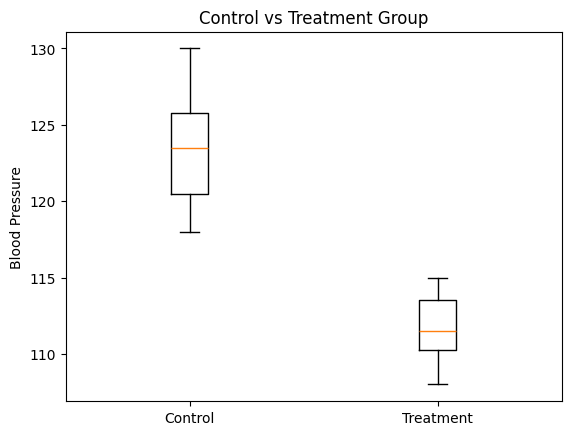

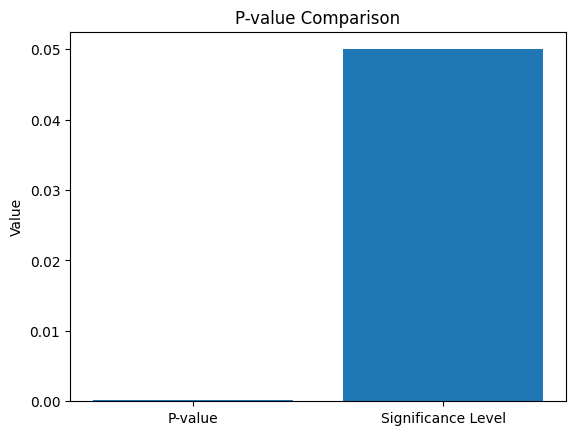

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Sample data
control = np.array([120, 125, 118, 130, 122, 126])
treatment = np.array([110, 115, 112, 108, 114, 111])

# Perform independent t-test
t_stat, p_value = stats.ttest_ind(
    control, treatment
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

# Hypothesis testing
if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Treatment has a significant effect.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant effect found.")

# Visualize data
plt.boxplot([control, treatment],
            labels=["Control", "Treatment"])

plt.title("Control vs Treatment Group")
plt.ylabel("Blood Pressure")
plt.show()

# Visualize p-value
plt.bar(["P-value", "Significance Level"],
        [p_value, 0.05])

plt.title("P-value Comparison")
plt.ylabel("Value")
plt.show()

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Sample dataset
X = [
    [2, 3, 1],
    [4, 5, 2],
    [6, 7, 3],
    [1, 2, 1],
    [7, 8, 4],
    [3, 4, 2]
]

y = [0, 1, 1, 0, 1, 0]

# Input value of k
k = int(input("Enter number of neighbors (k): "))

if k < 1 or k > len(X):
    print("Invalid value of k")
else:
    # Create KNN model
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    # Train model
    model.fit(X, y)

    # Get new patient features
    print("Enter patient symptoms:")

    features = [
        float(input("Feature 1: ")),
        float(input("Feature 2: ")),
        float(input("Feature 3: "))
    ]

    # Prediction
    prediction = model.predict([features])

    if prediction[0] == 1:
        print("Patient has the predicted condition.")
    else:
        print("Patient does not have the predicted condition.")

Enter number of neighbors (k): 8
Invalid value of k


In [5]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Create Decision Tree model
model = DecisionTreeClassifier(random_state=42)

# Train model
model.fit(X, y)

# Get flower measurements
sepal_length = float(input("Enter sepal length: "))
sepal_width = float(input("Enter sepal width: "))
petal_length = float(input("Enter petal length: "))
petal_width = float(input("Enter petal width: "))

# Input data
new_flower = [[
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
]]

# Predict species
prediction = model.predict(new_flower)

print("Predicted Iris Species:",
      iris.target_names[prediction[0]])

Enter sepal length: 7
Enter sepal width: 7
Enter petal length: 7
Enter petal width: 7
Predicted Iris Species: virginica
